In [1]:
!nvidia-smi

Sun Oct 25 08:29:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
REPO_URL = 'https://github.com/VladislavZherikhov/DLCV_course_project.git'
%cd /kaggle/working
!rm -rf repo && git clone -q -b baseline {REPO_URL} repo
%cd /kaggle/working/repo/baseline
!git log -1 --oneline
!pip install -q omegaconf

/kaggle/working
/kaggle/working/repo/baseline
0945b1d (HEAD -> baseline, origin/baseline, origin/HEAD) Baseline ResNet18 pipeline


data_root: /kaggle/input

train:
  images: /kaggle/input/datasets/shubhamkarande13/d-fire/train/images
  labels: /kaggle/input/datasets/shubhamkarande13/d-fire/train/labels
  17221 images, 17221 label files
  none          7833  (45.5%)
  smoke         4681  (27.2%)
  fire           944  (5.5%)
  fire_smoke    3763  (21.9%)

test:
  images: /kaggle/input/datasets/shubhamkarande13/d-fire/test/images
  labels: /kaggle/input/datasets/shubhamkarande13/d-fire/test/labels
  4306 images, 4306 label files
  none          2005  (46.6%)
  smoke         1186  (27.5%)
  fire           220  (5.1%)
  fire_smoke     895  (20.8%)

Saved data_check.png


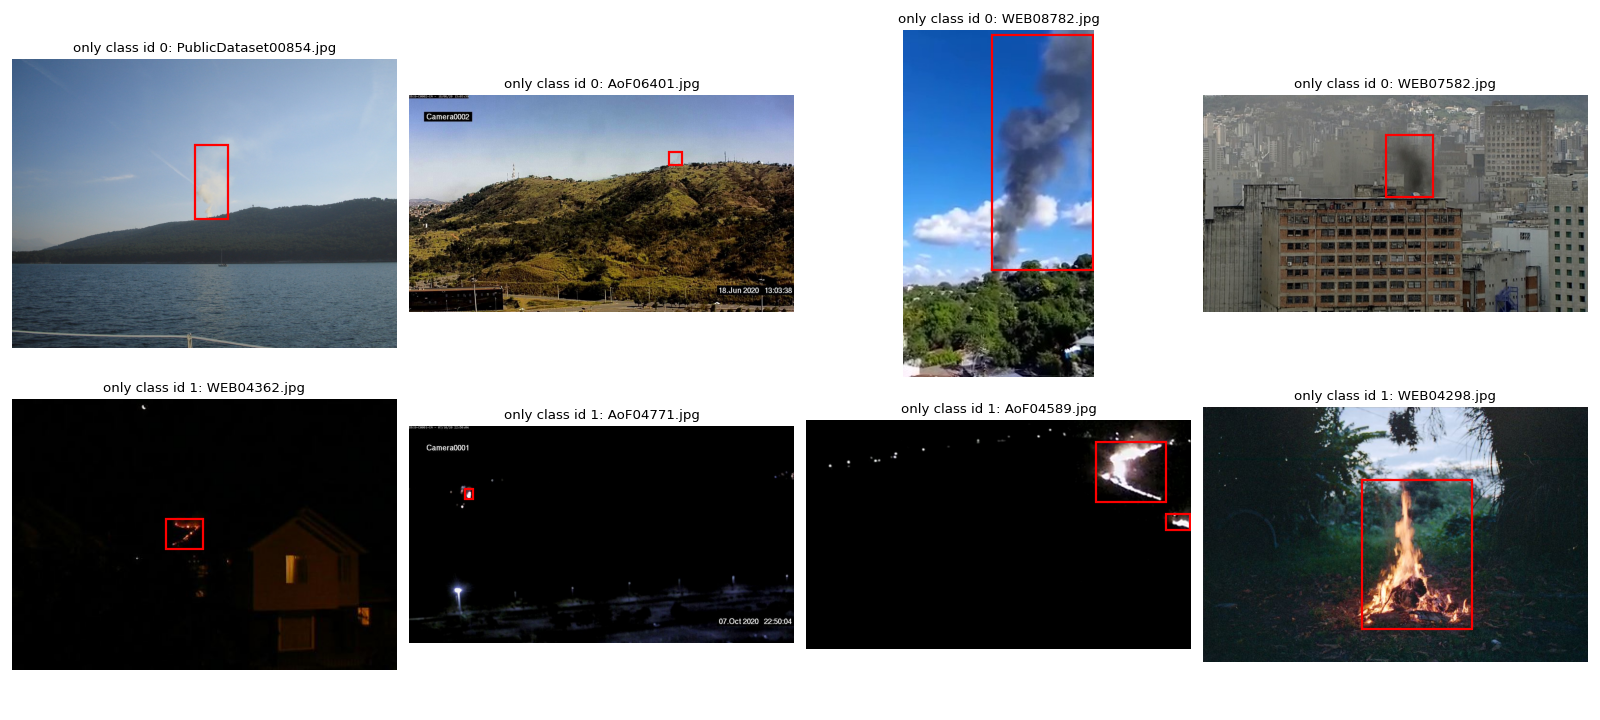

In [3]:
!python check_data.py
from IPython.display import Image, display
display(Image('data_check.png'))

In [4]:
!python -u main.py general.debug=true

08:43:08 | Experiment: resnet18_224_debug
08:43:08 | Output dir: /kaggle/working/outputs/resnet18_224_debug
08:43:08 | System: {"python": "3.13.15", "torch": "2.11.0+cu128", "cuda_available": true, "cpu_count": 4, "gpu": "Tesla T4", "gpu_count": 2, "gpu_memory_gb": 14.6, "cuda": "12.8"}
08:43:08 | Config:
general:
  exp_name: resnet18_224
  seed: 42
  debug: true
  debug_samples: 128
paths:
  data_root: /kaggle/input
  out_dir: /kaggle/working/outputs
data:
  smoke_id: 0
  fire_id: 1
  val_size: 0.15
  img_size: 224
model:
  name: resnet18
  pretrained: true
training:
  epochs: 15
  batch_size: 64
  lr: 0.0003
  weight_decay: 0.0001
  mixed_precision: true
  class_weights: true
  early_stopping: 5
  monitor: f1_macro
  num_workers: 4
  progress_bar: false
logging:
  log_interval: 50
  n_error_examples: 24
  zip_outputs: true

08:43:22 | Data root: /kaggle/input (parsed in 13.7s)
08:43:22 | Class distribution:
            train  val  test train % val % test %
none           58   58    6

In [5]:
EXP_NAME = 'resnet18_224'
!python -u main.py general.exp_name={EXP_NAME}

08:44:15 | Experiment: resnet18_224
08:44:15 | Output dir: /kaggle/working/outputs/resnet18_224
08:44:15 | System: {"python": "3.13.15", "torch": "2.11.0+cu128", "cuda_available": true, "cpu_count": 4, "gpu": "Tesla T4", "gpu_count": 2, "gpu_memory_gb": 14.6, "cuda": "12.8"}
08:44:15 | Config:
general:
  exp_name: resnet18_224
  seed: 42
  debug: false
  debug_samples: 128
paths:
  data_root: /kaggle/input
  out_dir: /kaggle/working/outputs
data:
  smoke_id: 0
  fire_id: 1
  val_size: 0.15
  img_size: 224
model:
  name: resnet18
  pretrained: true
training:
  epochs: 15
  batch_size: 64
  lr: 0.0003
  weight_decay: 0.0001
  mixed_precision: true
  class_weights: true
  early_stopping: 5
  monitor: f1_macro
  num_workers: 4
  progress_bar: false
logging:
  log_interval: 50
  n_error_examples: 24
  zip_outputs: true

08:44:28 | Data root: /kaggle/input (parsed in 13.1s)
08:44:28 | Class distribution:
            train   val  test train % val % test %
none         6658  1175  2005    45.5

TEST (4306 images)

accuracy             0.9408
precision_macro      0.9116
recall_macro         0.9018
f1_macro             0.9065
roc_auc_macro        0.9757
precision_weighted   0.9407
recall_weighted      0.9408
f1_weighted          0.9406
roc_auc_weighted     0.9875

Per-class metrics:
            precision  recall      f1  roc_auc  avg_precision  support
class                                                                 
none           0.9759  0.9711  0.9735   0.9958         0.9944     2005
smoke          0.9273  0.9359  0.9316   0.9861         0.9618     1186
fire           0.8390  0.7818  0.8094   0.9381         0.8292      220
fire_smoke     0.9043  0.9184  0.9113   0.9828         0.9413      895

Confusion matrix:
                 pred_none  pred_smoke  pred_fire  pred_fire_smoke
true_none             1947          43          2               13
true_smoke              43        1110          0               33
true_fire                3           4        172             

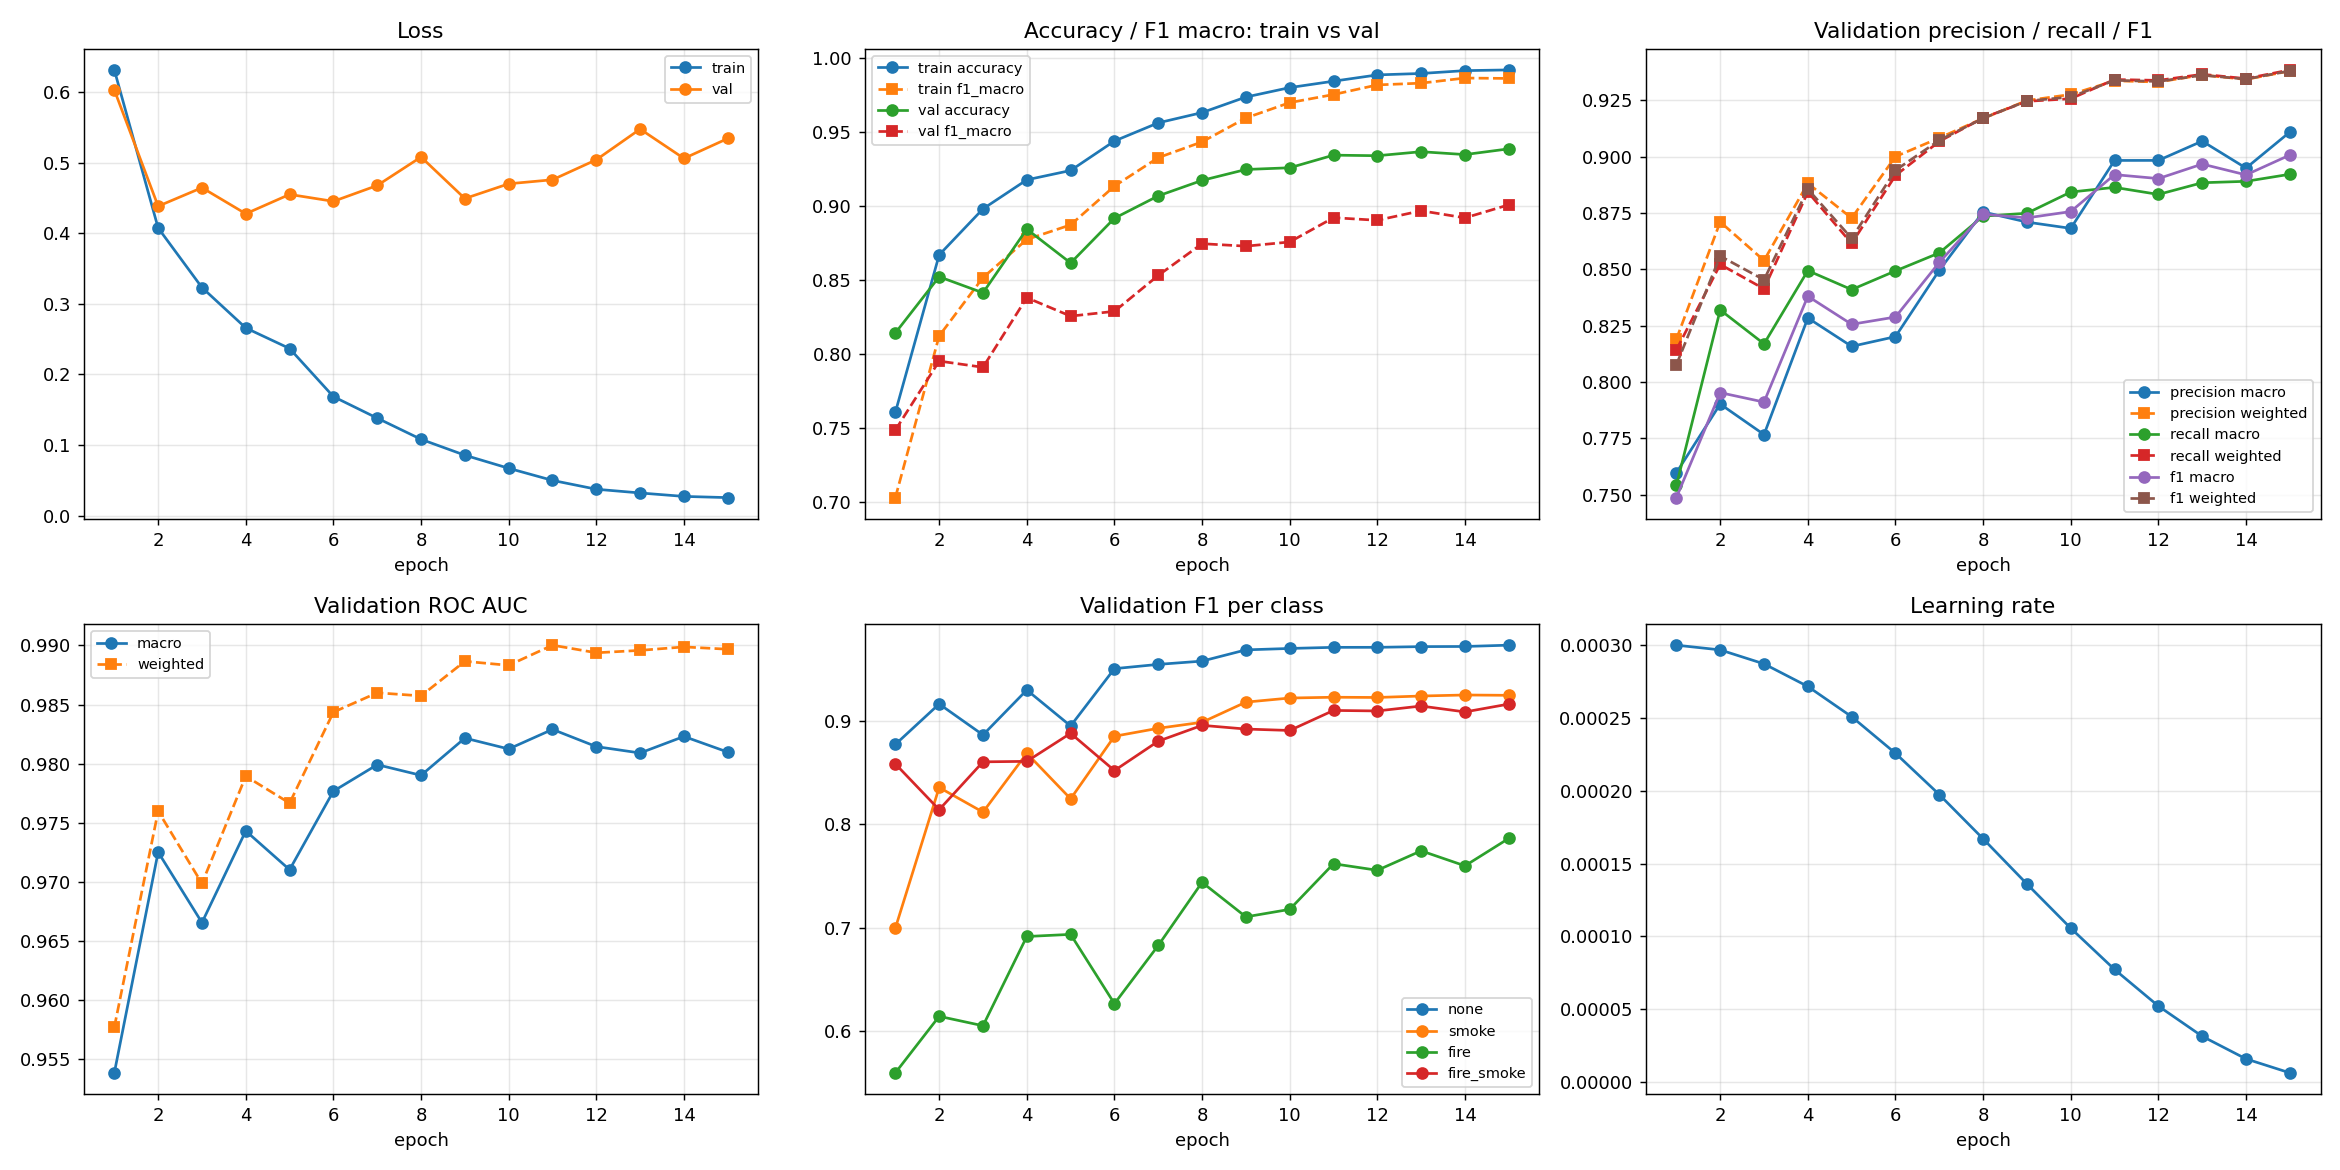

test_confusion_matrix.png


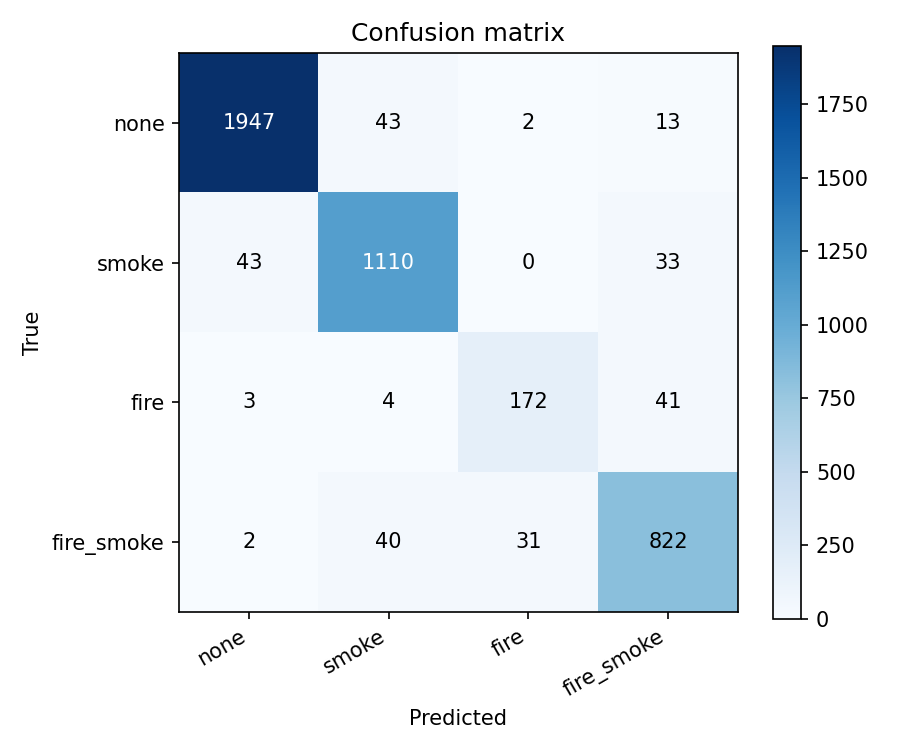

test_confusion_matrix_norm.png


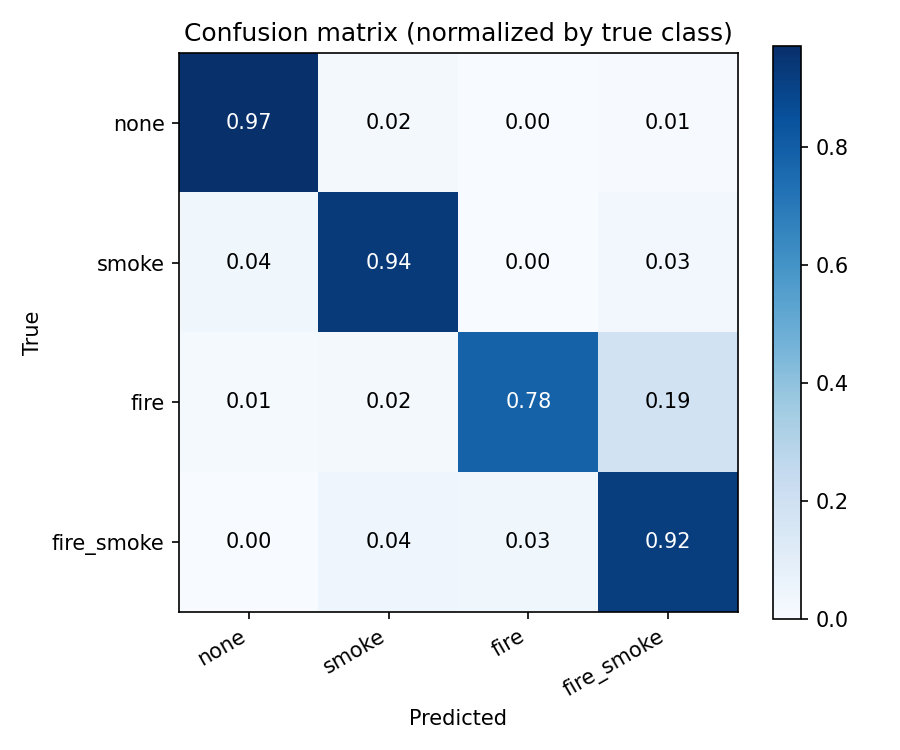

test_roc_pr_curves.png


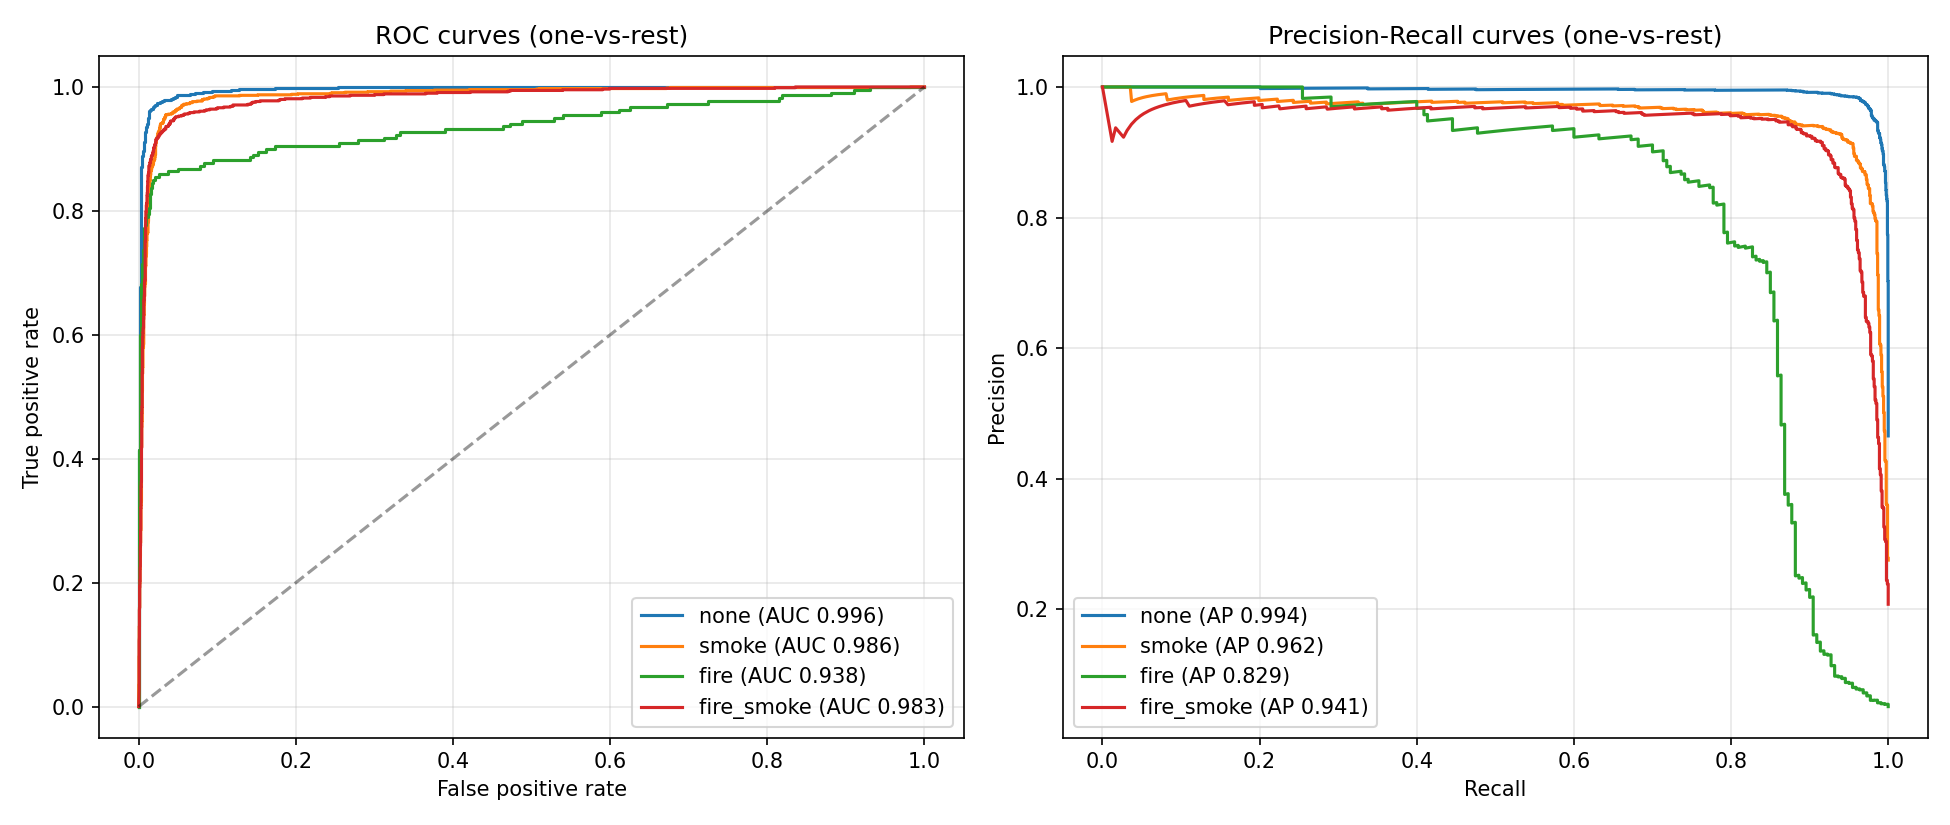

test_errors.png


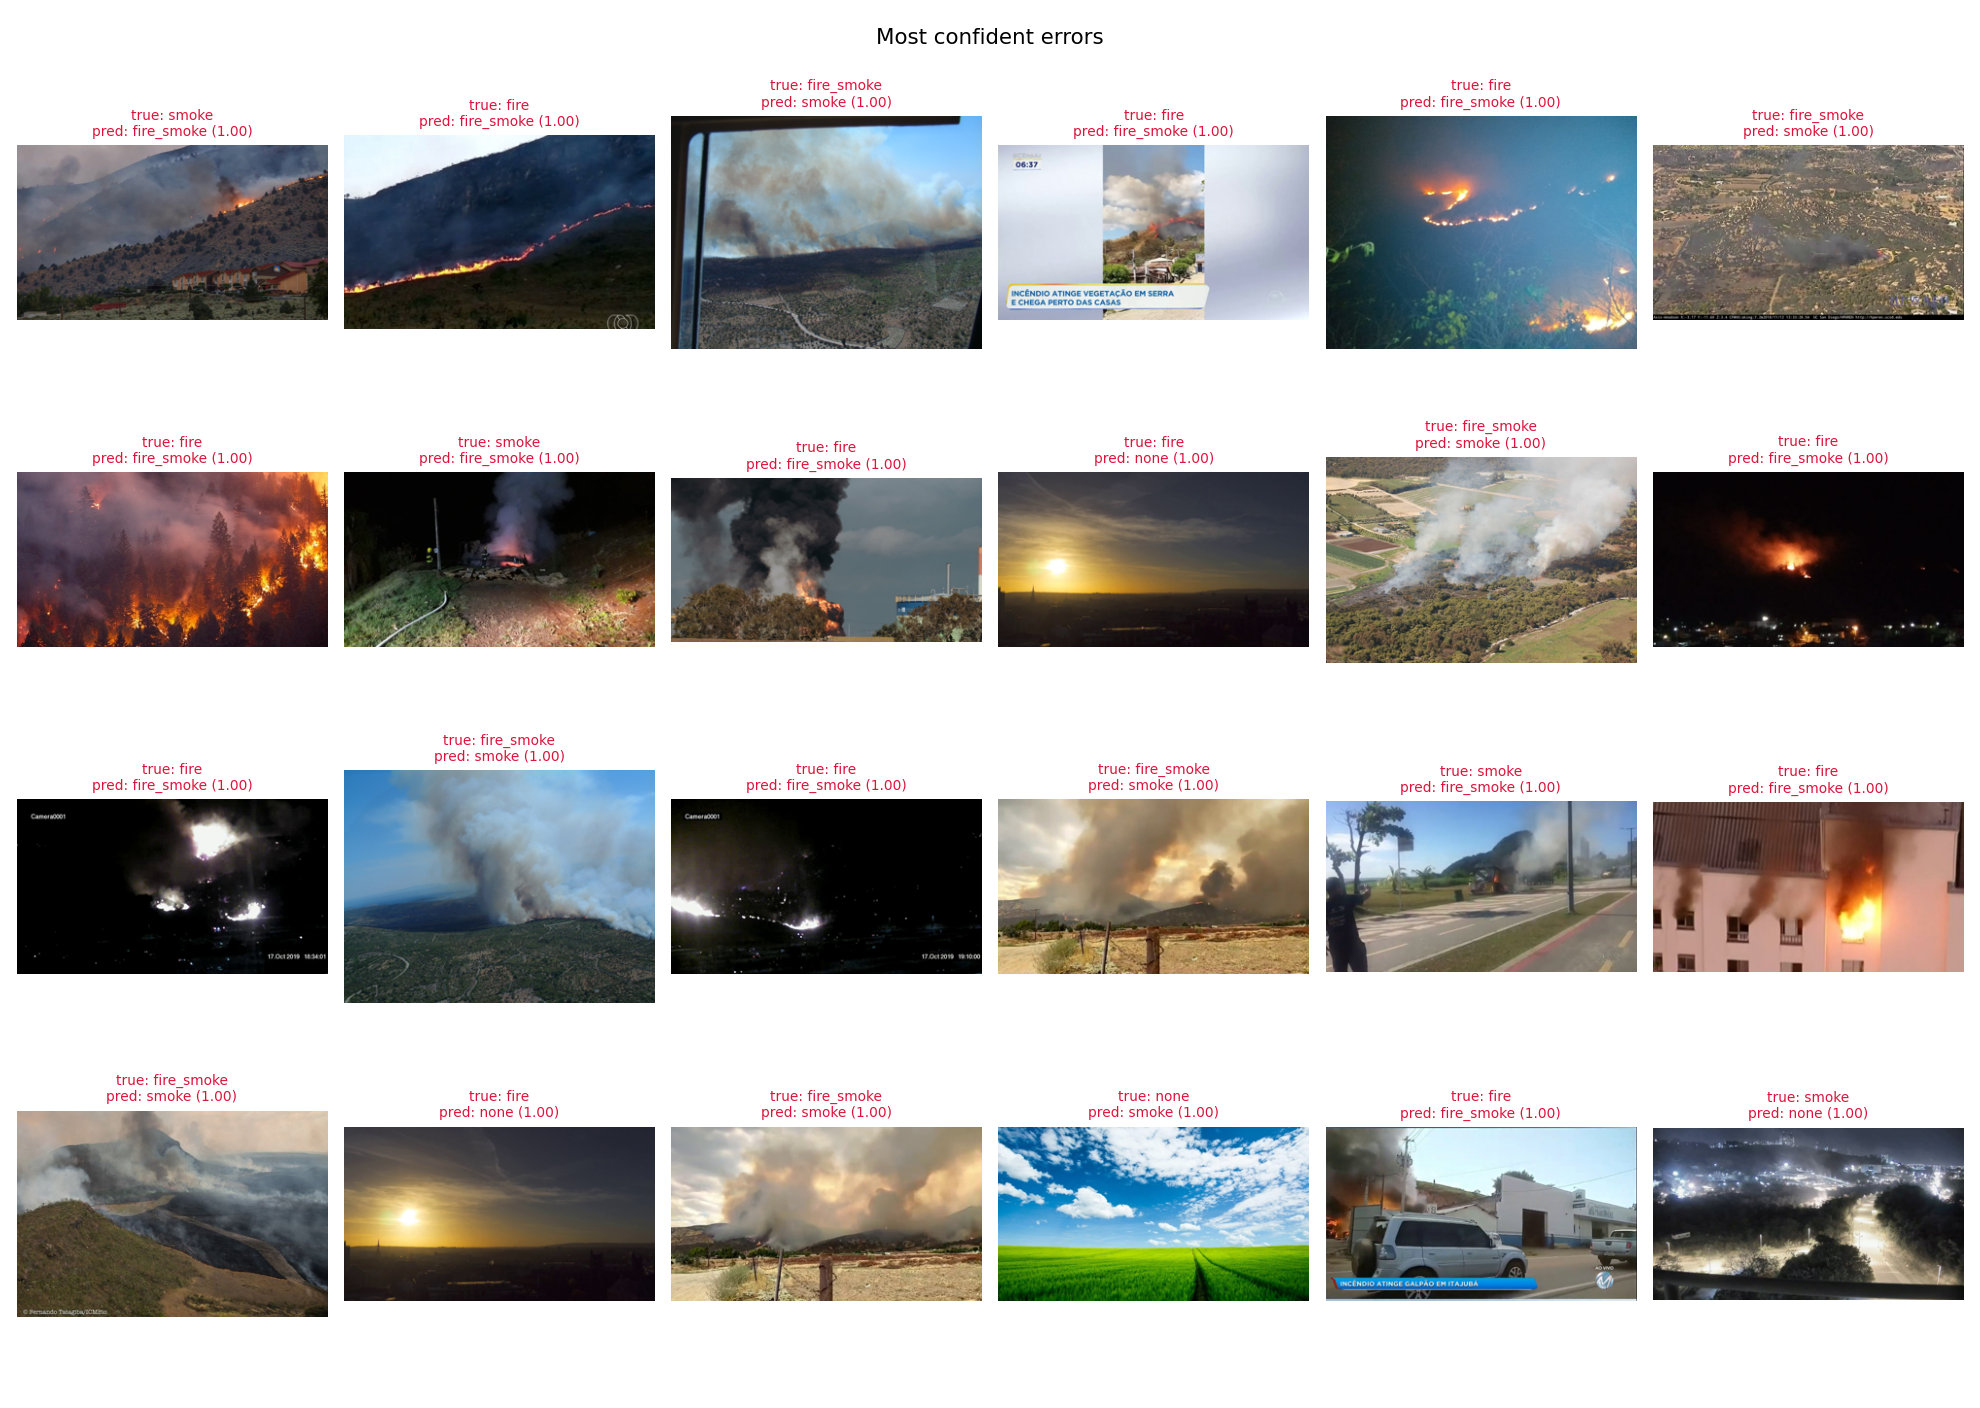

,epoch,lr,epoch_time_s,gpu_mem_gb,train_loss,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,train_roc_auc_macro,...,val_f1_none,val_precision_smoke,val_recall_smoke,val_f1_smoke,val_precision_fire,val_recall_fire,val_f1_fire,val_precision_fire_smoke,val_recall_fire_smoke,val_f1_fire_smoke
0,1,0.000300,553.6,0.93,0.631276,0.760691,0.691276,0.752985,0.703169,0.933615,...,0.877715,0.862213,0.588319,0.699407,0.535484,0.584507,0.558923,0.809077,0.915044,0.858804
1,2,0.000297,86.1,0.93,0.407423,0.866913,0.795748,0.850855,0.812262,0.973596,...,0.916983,0.837143,0.834758,0.835949,0.481928,0.845070,0.613811,0.933638,0.722124,0.814371
2,3,0.000287,85.1,0.93,0.323078,0.897958,0.834258,0.885109,0.851626,0.983008,...,0.886926,0.778068,0.849003,0.811989,0.514851,0.732394,0.604651,0.891841,0.831858,0.860806
3,4,0.000272,85.7,0.93,0.265815,0.917558,0.860011,0.905277,0.877328,0.988378,...,0.930537,0.867898,0.870370,0.869132,0.660256,0.725352,0.691275,0.829508,0.895575,0.861277
4,5,0.000251,86.6,0.93,0.236675,0.923862,0.869758,0.915340,0.887162,0.990599,...,0.895644,0.764277,0.896011,0.824918,0.658228,0.732394,0.693333,0.881533,0.895575,0.888499
5,6,0.000226,85.3,0.93,0.168546,0.943736,0.897607,0.935699,0.913329,0.995083,...,0.951261,0.906110,0.866097,0.885652,0.532020,0.760563,0.626087,0.902970,0.807080,0.852336
6,7,0.000197,83.7,0.93,0.138084,0.956003,0.917984,0.951908,0.932519,0.996567,...,0.955403,0.874488,0.913105,0.893380,0.662252,0.704225,0.682594,0.898711,0.863717,0.880866
7,8,0.000167,83.7,0.93,0.108087,0.962925,0.930429,0.959263,0.943170,0.997836,...,0.958580,0.902439,0.896011,0.899214,0.741259,0.746479,0.743860,0.905967,0.886726,0.896243
8,9,0.000136,83.8,0.93,0.085576,0.973410,0.948134,0.972813,0.959278,0.998596,...,0.969492,0.927431,0.910256,0.918763,0.695946,0.725352,0.710345,0.895018,0.890265,0.892635
9,10,0.000106,84.1,0.93,0.067038,0.979783,0.961559,0.978813,0.969636,0.999088,...,0.970865,0.918195,0.927350,0.922750,0.679245,0.760563,0.717608,0.897666,0.884956,0.891266


,exp_name,model,img_size,epochs,best_epoch,train_time_s,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,...,val_roc_auc_weighted,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc_macro,test_precision_weighted,test_recall_weighted,test_f1_weighted,test_roc_auc_weighted
0,resnet18_224_debug,resnet18,224,15,1,24,0.4766,0.4673,0.5127,0.4678,...,0.7476,0.5234,0.5182,0.5613,0.4906,0.8257,0.6175,0.5234,0.5182,0.7906
1,resnet18_224,resnet18,224,15,15,1755,0.9385,0.9109,0.8922,0.9007,...,0.9897,0.9408,0.9116,0.9018,0.9065,0.9757,0.9407,0.9408,0.9406,0.9875


In [6]:
import pandas as pd
EXP = f'/kaggle/working/outputs/{EXP_NAME}'
print(open(f'{EXP}/test_report.txt').read())
for name in ['training_curves.png', 'test_confusion_matrix.png', 'test_confusion_matrix_norm.png',
             'test_roc_pr_curves.png', 'test_errors.png']:
    print(name); display(Image(f'{EXP}/{name}'))
display(pd.read_csv(f'{EXP}/log.csv'))
display(pd.read_csv('/kaggle/working/outputs/results.csv'))